In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


In [5]:

# Define the CSV file path in a constant variable
CSV_FILE_PATH = "./../data/porto_district_all_geocoded.csv"

# Import the CSV file into a pandas DataFrame
df = pd.read_csv(CSV_FILE_PATH)



# Print the DataFrame shape (rows, columns)
print("\nDataFrame Shape:")
print(df.shape)

# Print all column names
print("\nColumns:")
print(df.columns.tolist())

# List each column's type and, for categorical columns, print categories and counts tab-separated.
print("\nColumn Types and Unique Values:")

for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        print(f"{col}: Numeric")
    else:
        print(f"{col}: Categorical")
        category_counts = df[col].value_counts(dropna=False)

        if len(category_counts) < 20:
            print("Category\tCount")
            for category, count in category_counts.items():
                print(f"\t{category}\t{count}")
            print()



DataFrame Shape:
(7000, 21)

Columns:
['id', 'municipality', 'operation', 'url', 'title', 'price_eur', 'area_m2', 'location', 'latitude', 'longitude', 'bedrooms', 'bathrooms', 'typology', 'property_type', 'floor', 'num_floors', 'has_garage', 'has_garden', 'scraped_at', 'matched_address', 'geocode_status']

Column Types and Unique Values:
id: Numeric
municipality: Categorical
Category	Count
	vila-nova-de-gaia	1926
	porto	1837
	matosinhos	1818
	maia	1276
	gondomar	143

operation: Categorical
Category	Count
	comprar	7000

url: Categorical
title: Categorical
price_eur: Numeric
area_m2: Numeric
location: Categorical
latitude: Numeric
longitude: Numeric
bedrooms: Numeric
bathrooms: Numeric
typology: Categorical
Category	Count
	T3	2115
	T2	1968
	T4	1091
	T1	1058
	T0	364
	T5	255
	T6	82
	T7	31
	T8	18
	T9	7
	T10	5
	T12	2
	T20	1
	T15	1
	T13	1
	T14	1

property_type: Categorical
Category	Count
	house	3601
	apartment	3397
	nan	2

floor: Numeric
num_floors: Numeric
has_garage: Numeric
has_garden: Nu

In [ ]:
df["price_m2"] = df["price_eur"] / df["area_m2"]
print("\nDataFrame with price per square meter:")
print(df[["price_eur", "area_m2", "price_m2"]].head())


DataFrame with price per square meter:
   price_eur  area_m2     price_m2
0     369000       80  4612.500000
1     760000      227  3348.017621
2     250000       54  4629.629630
3     330000       42  7857.142857
4    1990000      489  4069.529652


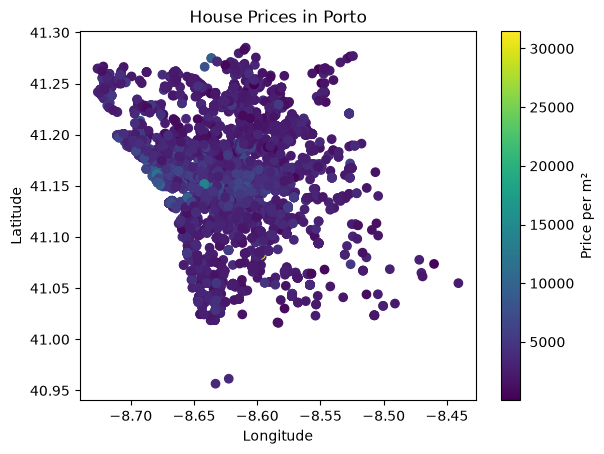

In [ ]:
# Scatter plot of house via latitude and longitude with color for the price per square meter

# Filter for municipality = Porto

plt.scatter(df["longitude"], df["latitude"], c=df["price_m2"], cmap="viridis")
plt.colorbar(label="Price per m²")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("House Prices in Porto")
plt.show()

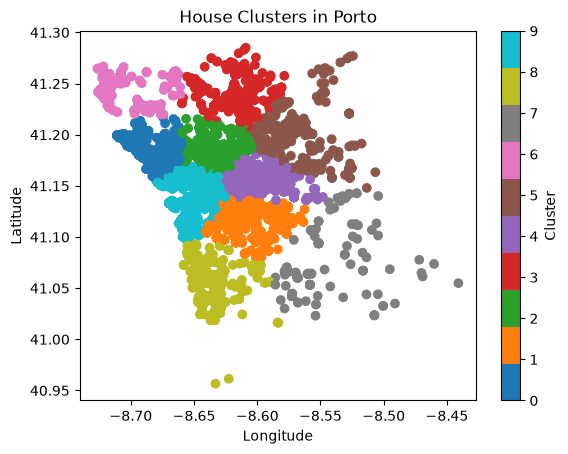

In [26]:
# Run k-means clustering on valid latitude and longitude coordinates to group houses into geographic clusters.

K = 10
coordinates = df[["latitude", "longitude"]]
valid_coordinates = coordinates.notna().all(axis=1)

kmeans = KMeans(n_clusters=K, random_state=0, n_init="auto")
df["cluster"] = pd.NA
df.loc[valid_coordinates, "cluster"] = kmeans.fit_predict(
    coordinates.loc[valid_coordinates]
)

# plot the clusters on a scatter plot with different colors for each cluster
plot_df = df.loc[valid_coordinates]

plt.scatter(
    plot_df["longitude"],
    plot_df["latitude"],
    c=plot_df["cluster"].astype(int),
    cmap="tab10"
)
plt.colorbar(label="Cluster")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("House Clusters in Porto")
plt.show()


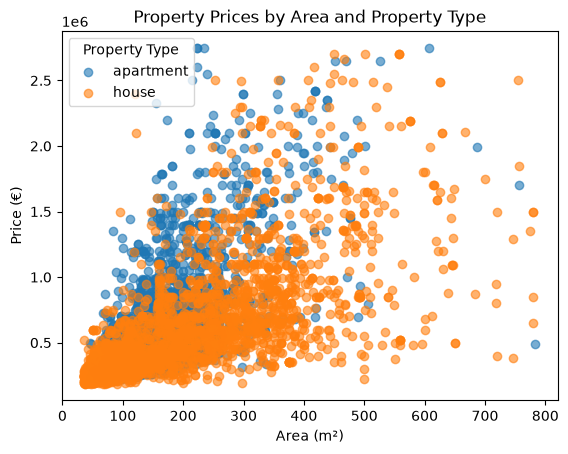

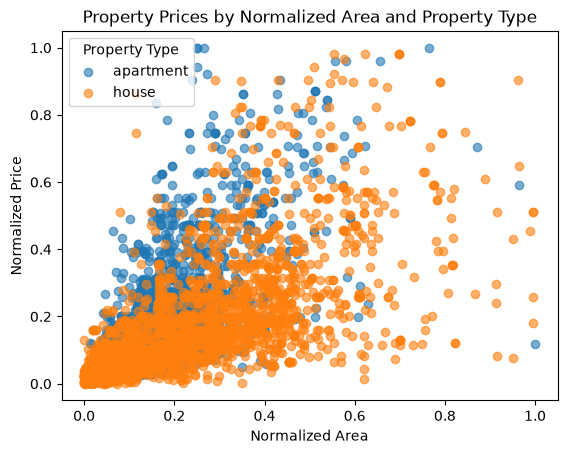

In [19]:
# Scatter plot of price versus area, colored by property type

plot_df = df.dropna(subset=["area_m2", "price_eur", "property_type"])

# Remove outliers based on the 1st and 99th percentiles for area and price
area_lower_bound = plot_df["area_m2"].quantile(0.01)
area_upper_bound = plot_df["area_m2"].quantile(0.99)
area_mask = (plot_df["area_m2"] >= area_lower_bound) & (plot_df["area_m2"] <= area_upper_bound)

price_lower_bound = plot_df["price_eur"].quantile(0.01)
price_upper_bound = plot_df["price_eur"].quantile(0.99)
price_mask = (plot_df["price_eur"] >= price_lower_bound) & (plot_df["price_eur"] <= price_upper_bound)

# Apply the masks to filter the data
plot_df = plot_df[area_mask & price_mask]

for property_type, group in plot_df.groupby("property_type"):
    plt.scatter(
        group["area_m2"],
        group["price_eur"],
        label=property_type,
        alpha=0.6
    )

plt.xlabel("Area (m²)")
plt.ylabel("Price (€)")
plt.title("Property Prices by Area and Property Type")
plt.legend(title="Property Type")
plt.show()


#Normalize the area and price for better visualization

plot_df["area_m2_normalized"] = (plot_df["area_m2"] - plot_df["area_m2"].min()) / (plot_df["area_m2"].max() - plot_df["area_m2"].min())
plot_df["price_eur_normalized"] = (plot_df["price_eur"] - plot_df["price_eur"].min()) / (plot_df["price_eur"].max() - plot_df["price_eur"].min())

# Scatter plot of normalized price versus normalized area, colored by property type
for property_type, group in plot_df.groupby("property_type"):
    plt.scatter(
        group["area_m2_normalized"],
        group["price_eur_normalized"],
        label=property_type,
        alpha=0.6
    )

plt.xlabel("Normalized Area")
plt.ylabel("Normalized Price")
plt.title("Property Prices by Normalized Area and Property Type")
plt.legend(title="Property Type")
plt.show()

